# Figure for Section 3.3.1, benchmarking of CombFold on complexes with known structures

Panels
* **A** accuracy of the highest-confidence assembly per complex (TM-score classes)
* **B** RNA polymerase I, experimental structure next to the CF assembly, coloured by subunit
* **C** TM-score against CF confidence
* **D** accuracy among all complexes and among complexes above the confidence threshold

Run on the cluster (needs the structure files). Requires polars, scipy, gemmi, matplotlib and
`pymol-open-source` (`pip install pymol-open-source`). Run the cells in order from the top.

In [1]:
import json
from pathlib import Path

import gemmi
import matplotlib.pyplot as plt
import polars as pl
from matplotlib.gridspec import GridSpecFromSubplotSpec
from matplotlib.patches import Patch
from pymol import cmd
from scipy.stats import spearmanr

plt.rcParams.update({
    "pdf.fonttype": 42,
    "font.family": "DejaVu Sans",
    "font.size": 7,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

## Configuration

In [8]:
PARQUET = "/cluster/project/beltrao/kdammer/master_thesis/data/Pipeline/18_CP_model_based_on_pae/cf_pdb_structure_similarity/cf_pdb_eval_all_metrics.parquet"
EXPECTED_N_COMPLEXES = 41
WORK_DIR = Path("cf_benchmark_figure_work")
OUT_PDF = "cf_benchmark.pdf"

# accuracy classes and confidence threshold, used consistently in all panels
TM_HIGH_ACCURACY = 0.8        # TM-score > 0.8
TM_ACCEPTABLE_ACCURACY = 0.7  # 0.7 < TM-score <= 0.8
CF_CONFIDENCE_THRESHOLD = 80  # CF confidence >= 80

# colours, matching the Stoic benchmark tables
HEADER_BLUE = "#1f3b8c"
HIGH_ACCURACY_COLOUR = "#1f3b8c"
ACCEPTABLE_ACCURACY_COLOUR = "#8fa8d8"
LOW_ACCURACY_COLOUR = "#c8c8c8"
EDGE_COLOR = "#d9dee8"

POL1_AC = "CPX-1664"
POL1_LABEL = "RNA polymerase I"
POL1_SHORT_LABEL = "Pol I"
POL1_PDB_ID = "9G1V"

# (legend label, UniProt accession, colour)
SUBUNIT_COLOURS = [
    ("A190", "P10964", "#4C72B0"),
    ("A135", "P22138", "#DD8452"),
    ("AC40", "P07703", "#55A868"),
    ("AC19", "P28000", "#C44E52"),
    ("A12", "P32529", "#8172B3"),
    ("A14", "P50106", "#937860"),
    ("A43", "P46669", "#DA8BC3"),
    ("Rpb5", "P20434", "#8C8C8C"),
    ("Rpb6", "P20435", "#CCB974"),
    ("Rpb8", "P20436", "#64B5CD"),
    ("Rpb10", "P22139", "#1B7837"),
    ("Rpb12", "P40422", "#B2182B"),
    ("A49", "Q01080", "#E6AB02"),
    ("A34.5", "P47006", "#2166AC"),
]

RENDER_SIZE_PX = 1600   # per structure image
VIEW_TURN_X_DEGREES = -90  # TODO adjust the common orientation if desired
VIEW_TURN_Y_DEGREES = 0

## Benchmark data, one assembly per complex (highest CF confidence)

In [9]:
benchmark_all_outputs = pl.read_parquet(PARQUET)
assert "CF_confidence" not in benchmark_all_outputs.columns, "parquet already has CF_confidence, check which one to use"
for required_column in ["combfold_output_path", "usalign_pred_dir", "usalign_cpx_tm_score", "n_proteins", "complex_ac"]:
    assert required_column in benchmark_all_outputs.columns, f"{required_column} missing in parquet"

# CF confidence per output, from the confidence.txt next to each CF output
confidence_by_output_path = {}
for combfold_output_dir in {Path(output_path).parent for output_path in benchmark_all_outputs["combfold_output_path"]}:
    confidence_file = combfold_output_dir / "confidence.txt"
    assert confidence_file.exists(), f"missing {confidence_file}"
    with open(confidence_file) as confidence_handle:
        confidence_by_output_path.update(dict(line.split() for line in confidence_handle if line.strip()))
outputs_without_confidence = set(benchmark_all_outputs["combfold_output_path"]) - set(confidence_by_output_path)
assert not outputs_without_confidence, f"{len(outputs_without_confidence)} outputs without confidence, e.g. {next(iter(outputs_without_confidence))}"

benchmark_per_complex = (
    benchmark_all_outputs
    .with_columns(
        CF_confidence=pl.col("combfold_output_path").replace_strict(confidence_by_output_path, return_dtype=pl.Float64),
        usalign_pdb_path=pl.col("usalign_pred_dir") + "/complex/usalign.pdb",
    )
    .filter(pl.col("n_proteins") > 2)
    .sort("CF_confidence", descending=True)
    .group_by("complex_ac", maintain_order=True)
    .head(1)
    .with_columns(
        accuracy_class=pl.when(pl.col("usalign_cpx_tm_score") > TM_HIGH_ACCURACY).then(pl.lit("high"))
        .when(pl.col("usalign_cpx_tm_score") > TM_ACCEPTABLE_ACCURACY).then(pl.lit("acceptable"))
        .otherwise(pl.lit("low")),
        is_confident=pl.col("CF_confidence") >= CF_CONFIDENCE_THRESHOLD,
    )
)
assert benchmark_per_complex.height == EXPECTED_N_COMPLEXES, \
    f"expected {EXPECTED_N_COMPLEXES} complexes, got {benchmark_per_complex.height}"
assert benchmark_per_complex["complex_ac"].n_unique() == benchmark_per_complex.height
assert benchmark_per_complex["usalign_cpx_tm_score"].null_count() == 0
assert benchmark_per_complex["CF_confidence"].null_count() == 0
assert POL1_AC in set(benchmark_per_complex["complex_ac"]), "example complex missing"
n_complexes = benchmark_per_complex.height
class_counts = dict(benchmark_per_complex["accuracy_class"].value_counts().iter_rows())
spearman_rho, spearman_pvalue = spearmanr(benchmark_per_complex["CF_confidence"], benchmark_per_complex["usalign_cpx_tm_score"])

accuracy_by_confidence = pl.DataFrame({
    "subset": ["All", f"CF \u2265 {CF_CONFIDENCE_THRESHOLD}"],
    "n_complexes": [n_complexes, int(benchmark_per_complex["is_confident"].sum())],
    "n_accurate": [
        int((benchmark_per_complex["accuracy_class"] != "low").sum()),
        int((benchmark_per_complex.filter(pl.col("is_confident"))["accuracy_class"] != "low").sum()),
    ],
}).with_columns(fraction_accurate=pl.col("n_accurate") / pl.col("n_complexes"))

# numbers for the text
print(f"n = {n_complexes} complexes, Spearman rho = {spearman_rho:.2f} (p = {spearman_pvalue:.1e})")
print("accuracy classes:", class_counts)
print(accuracy_by_confidence)
missed_accurate = benchmark_per_complex.filter(~pl.col("is_confident") & (pl.col("accuracy_class") != "low")).height
print(f"accurate assemblies below the confidence threshold: {missed_accurate}")
print(benchmark_per_complex.filter(pl.col("complex_ac") == POL1_AC)
      .select("complex_ac", "usalign_cpx_tm_score", "CF_confidence"))

n = 41 complexes, Spearman rho = 0.54 (p = 2.6e-04)
accuracy classes: {'low': 21, 'acceptable': 4, 'high': 16}
shape: (2, 4)
┌─────────┬─────────────┬────────────┬───────────────────┐
│ subset  ┆ n_complexes ┆ n_accurate ┆ fraction_accurate │
│ ---     ┆ ---         ┆ ---        ┆ ---               │
│ str     ┆ i64         ┆ i64        ┆ f64               │
╞═════════╪═════════════╪════════════╪═══════════════════╡
│ All     ┆ 41          ┆ 20         ┆ 0.487805          │
│ CF ≥ 80 ┆ 19          ┆ 16         ┆ 0.842105          │
└─────────┴─────────────┴────────────┴───────────────────┘
accurate assemblies below the confidence threshold: 4
shape: (1, 3)
┌────────────┬──────────────────────┬───────────────┐
│ complex_ac ┆ usalign_cpx_tm_score ┆ CF_confidence │
│ ---        ┆ ---                  ┆ ---           │
│ str        ┆ f64                  ┆ f64           │
╞════════════╪══════════════════════╪═══════════════╡
│ CPX-1664   ┆ 0.92602              ┆ 86.5867       │
└──────────

## Structure preparation (protein chains only, Pol I)

In [10]:
def read_protein_only(path: str) -> gemmi.Structure:
    """Drop waters, ligands and nucleic acids, keep the first model."""
    structure = gemmi.read_structure(path)
    structure.setup_entities()
    structure.remove_ligands_and_waters()
    for model in structure:
        nucleic_chain_indices = [
            i for i, chain in enumerate(model)
            if chain.get_polymer().check_polymer_type()
            in (gemmi.PolymerType.Dna, gemmi.PolymerType.Rna, gemmi.PolymerType.DnaRnaHybrid)
        ]
        for i in reversed(nucleic_chain_indices):
            del model[i]
    structure.remove_empty_chains()
    while len(structure) > 1:
        del structure[1]
    return structure


def ca_positions_by_residue(chain: gemmi.Chain) -> dict:
    return {res.seqid.num: res["CA"][0].pos for res in chain if res.find_atom("CA", "*")}


pol1_row = benchmark_per_complex.filter(pl.col("complex_ac") == POL1_AC).row(0, named=True)
pol1_reference = read_protein_only(pol1_row["reference_pdb_path"])
pol1_prediction = read_protein_only(pol1_row["usalign_pdb_path"])
pol1_chain_mapping = json.loads(pol1_row["chain_mapping"])
assert all(len(cf_chains) == 1 and len(ref_chains) == 1 for cf_chains, ref_chains in pol1_chain_mapping.values()), \
    "expected one copy per subunit"

# the assembly must already be superposed on the reference (US-align output)
first_uniprot = next(iter(pol1_chain_mapping))
ref_ca = ca_positions_by_residue(pol1_reference[0][pol1_chain_mapping[first_uniprot][1][0]])
pred_ca = ca_positions_by_residue(pol1_prediction[0][pol1_chain_mapping[first_uniprot][0][0]])
common_residue_numbers = sorted(set(ref_ca) & set(pred_ca))
assert common_residue_numbers, "no common residue numbers between reference and assembly"
median_distance = sorted(ref_ca[n].dist(pred_ca[n]) for n in common_residue_numbers)[len(common_residue_numbers) // 2]
assert median_distance < 5, f"assembly does not seem superposed ({median_distance:.1f} A)"

# show only predicted residues that are resolved in the reference (as for the TM-score)
n_residues_before = sum(len(chain) for chain in pol1_prediction[0])
for cf_chains, ref_chains in pol1_chain_mapping.values():
    resolved_numbers = set(ca_positions_by_residue(pol1_reference[0][ref_chains[0]]))
    pred_chain = pol1_prediction[0][cf_chains[0]]
    for i in reversed(range(len(pred_chain))):
        if pred_chain[i].seqid.num not in resolved_numbers:
            del pred_chain[i]
n_residues_after = sum(len(chain) for chain in pol1_prediction[0])
print(f"showing {n_residues_after}/{n_residues_before} predicted residues")

WORK_DIR.mkdir(exist_ok=True)
prepared_structure_paths = {}
for structure, column, kind in [(pol1_reference, 1, "ref"), (pol1_prediction, 0, "pred")]:
    chain_to_uniprot = {chains[column][0]: uniprot for uniprot, chains in pol1_chain_mapping.items()}
    unmapped_chains = [chain.name for chain in structure[0] if chain.name not in chain_to_uniprot]
    for chain_name in unmapped_chains:  # e.g. nanobodies in the reference
        print(f"  {kind}: dropping unmapped chain {chain_name}")
        structure[0].remove_chain(chain_name)
    for chain in structure[0]:
        chain.name = chain_to_uniprot[chain.name]
    structure.setup_entities()
    prepared_structure_paths[kind] = WORK_DIR / f"{POL1_AC}_{kind}.cif"
    structure.make_mmcif_document().write_file(str(prepared_structure_paths[kind]))


showing 3972/5236 predicted residues


## Rendering, reference and assembly separately but in the same view and scale

In [11]:
import os
import time


def hex_to_rgb_fraction(hex_colour: str) -> list:
    return [int(hex_colour[i:i + 2], 16) / 255 for i in (1, 3, 5)]


n_available_cores = len(os.sched_getaffinity(0))
print(f"rendering with {n_available_cores} threads")

cmd.reinitialize()
for setting_name, setting_value in {
    "bg_rgb": "white", "ray_opaque_background": 1, "ray_trace_mode": 0, "ray_shadows": 0,
    "antialias": 1, "ambient": 0.5, "direct": 0.55, "reflect": 0.25, "specular": 0.0,
    "cartoon_fancy_helices": 1, "cartoon_loop_radius": 0.35, "depth_cue": 0, "orthoscopic": 1,
    "max_threads": n_available_cores,
}.items():
    cmd.set(setting_name, setting_value)

colour_by_uniprot = {uniprot: hex_colour for _, uniprot, hex_colour in SUBUNIT_COLOURS}
for uniprot, hex_colour in colour_by_uniprot.items():
    cmd.set_color(f"c_{uniprot}", hex_to_rgb_fraction(hex_colour))

for kind, structure_path in prepared_structure_paths.items():
    object_name = f"{POL1_AC}_{kind}"
    cmd.load(str(structure_path), object_name)
    missing_colours = set(cmd.get_chains(object_name)) - set(colour_by_uniprot)
    assert not missing_colours, f"{object_name}: no colour for {missing_colours}"
    for chain in cmd.get_chains(object_name):
        cmd.color(f"c_{chain}", f"{object_name} and chain {chain}")

# one common view for both images, defined on the reference
cmd.hide("everything")
cmd.orient(f"{POL1_AC}_ref")
cmd.turn("x", VIEW_TURN_X_DEGREES)
cmd.turn("y", VIEW_TURN_Y_DEGREES)
cmd.zoom("all", buffer=2, complete=1)
common_view = cmd.get_view()

rendered_image_paths = {}
for kind in ["ref", "pred"]:
    object_name = f"{POL1_AC}_{kind}"
    cmd.hide("everything")
    cmd.show("cartoon", object_name)
    cmd.set_view(common_view)
    image_path = WORK_DIR / f"{object_name}.png"
    render_start = time.time()
    cmd.png(str(image_path), width=RENDER_SIZE_PX, height=RENDER_SIZE_PX, dpi=600, ray=1)
    assert image_path.exists(), f"render failed for {object_name}"
    print(f"{object_name} rendered in {time.time() - render_start:.0f} s")
    rendered_image_paths[kind] = image_path

rendering with 4 threads
CPX-1664_ref rendered in 94 s
CPX-1664_pred rendered in 83 s


## Figure

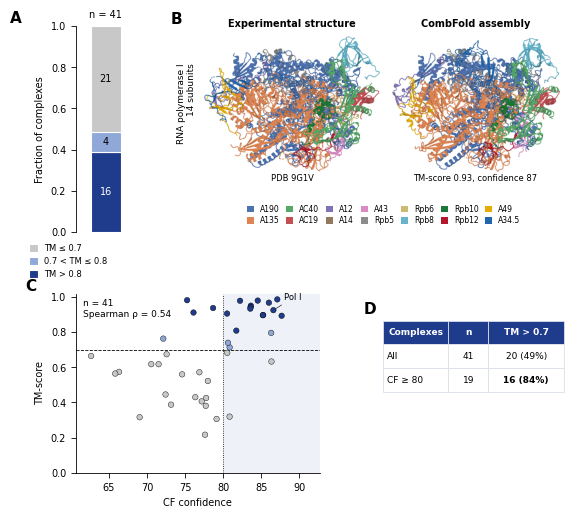

In [12]:
def crop_to_common_box(rgb_images: list, padding_px: int = 10) -> list:
    """Crop all images to the same box, so that they keep the same scale and position."""
    assert len({image.shape for image in rgb_images}) == 1, "renders must have the same size"
    content_mask = sum((image[:, :, :3].min(axis=2) < 0.98) for image in rgb_images) > 0
    content_rows, content_columns = content_mask.nonzero()
    assert content_rows.size > 0, "renders are empty"
    top, bottom = max(content_rows.min() - padding_px, 0), content_rows.max() + padding_px
    left, right = max(content_columns.min() - padding_px, 0), content_columns.max() + padding_px
    return [image[top:bottom, left:right] for image in rgb_images]


def add_panel_letter(axis, letter, x_offset=-0.02, y_offset=1.0):
    axis.text(x_offset, y_offset, letter, transform=axis.transAxes, fontsize=11, fontweight="bold",
              va="bottom", ha="right")


structure_kinds = ["ref", "pred"]
cropped_images = dict(zip(structure_kinds, crop_to_common_box([plt.imread(rendered_image_paths[kind]) for kind in structure_kinds])))

benchmark_figure = plt.figure(figsize=(6.3, 5.8))
outer_grid = benchmark_figure.add_gridspec(2, 2, height_ratios=[1.15, 1], width_ratios=[0.5, 3],
                                           hspace=0.32, wspace=0.32)

# ---- A, accuracy classes
axis_accuracy = benchmark_figure.add_subplot(outer_grid[0, 0])
class_order = [("high", f"TM > {TM_HIGH_ACCURACY}", HIGH_ACCURACY_COLOUR),
               ("acceptable", f"{TM_ACCEPTABLE_ACCURACY} < TM ≤ {TM_HIGH_ACCURACY}", ACCEPTABLE_ACCURACY_COLOUR),
               ("low", f"TM ≤ {TM_ACCEPTABLE_ACCURACY}", LOW_ACCURACY_COLOUR)]
bar_bottom = 0.0
for class_name, class_label, class_colour in class_order:
    class_count = class_counts.get(class_name, 0)
    class_fraction = class_count / n_complexes
    axis_accuracy.bar(0, class_fraction, bottom=bar_bottom, width=0.6, color=class_colour,
                      edgecolor="white", linewidth=0.8, label=class_label)
    if class_count > 0:
        axis_accuracy.text(0, bar_bottom + class_fraction / 2, f"{class_count}",
                           ha="center", va="center", fontsize=7,
                           color="white" if class_name == "high" else "black")
    bar_bottom += class_fraction
axis_accuracy.set_xlim(-0.6, 0.6)
axis_accuracy.set_ylim(0, 1)
axis_accuracy.set_xticks([])
axis_accuracy.spines["bottom"].set_visible(False)
axis_accuracy.set_ylabel("Fraction of complexes")
axis_accuracy.set_title(f"n = {n_complexes}", fontsize=7)
axis_accuracy.legend(loc="upper left", bbox_to_anchor=(-0.9, -0.02), frameon=False, fontsize=6,
                     handlelength=1.0, handleheight=1.0, reverse=True)
add_panel_letter(axis_accuracy, "A", x_offset=-0.9)

# ---- B, Pol I reference next to the CF assembly
structure_grid = GridSpecFromSubplotSpec(2, 2, subplot_spec=outer_grid[0, 1], height_ratios=[1, 0.25],
                                         hspace=0.12, wspace=0.03)
column_titles = {"ref": "Experimental structure", "pred": "CombFold assembly"}
column_footers = {
    "ref": f"PDB {POL1_PDB_ID}",
    "pred": f"TM-score {pol1_row['usalign_cpx_tm_score']:.2f}, confidence {pol1_row['CF_confidence']:.0f}",
}
for column_index, kind in enumerate(structure_kinds):
    structure_axis = benchmark_figure.add_subplot(structure_grid[0, column_index])
    structure_axis.imshow(cropped_images[kind])
    structure_axis.set_axis_off()
    structure_axis.set_title(column_titles[kind], fontsize=7, fontweight="bold")
    structure_axis.text(0.5, -0.01, column_footers[kind], transform=structure_axis.transAxes,
                        ha="center", va="top", fontsize=6)
    if kind == "ref":
        structure_axis.text(-0.04, 0.5, f"{POL1_LABEL}\n{len(pol1_chain_mapping)} subunits",
                            transform=structure_axis.transAxes, rotation=90, ha="right", va="center", fontsize=6.5)
        add_panel_letter(structure_axis, "B", x_offset=-0.12, y_offset=1.06)

legend_axis = benchmark_figure.add_subplot(structure_grid[1, :])
legend_axis.set_axis_off()
legend_axis.legend(
    handles=[Patch(facecolor=hex_colour, edgecolor="none", label=label) for label, _, hex_colour in SUBUNIT_COLOURS],
    loc="lower center", ncol=7, frameon=False, fontsize=5.5, handlelength=0.9, handleheight=0.9,
    columnspacing=0.9, labelspacing=0.3,
)

# ---- C, TM-score against CF confidence
bottom_grid = outer_grid[1, :].subgridspec(1, 2, width_ratios=[1.35, 1], wspace=0.3)
axis_scatter = benchmark_figure.add_subplot(bottom_grid[0])
colour_by_class = {class_name: class_colour for class_name, _, class_colour in class_order}
axis_scatter.axvspan(CF_CONFIDENCE_THRESHOLD, 100, color="#eef1f8", zorder=0, lw=0)
axis_scatter.axhline(TM_ACCEPTABLE_ACCURACY, color="black", lw=0.6, ls="--", zorder=1)
axis_scatter.axvline(CF_CONFIDENCE_THRESHOLD, color="black", lw=0.6, ls=":", zorder=1)
axis_scatter.scatter(
    benchmark_per_complex["CF_confidence"], benchmark_per_complex["usalign_cpx_tm_score"],
    c=[colour_by_class[class_name] for class_name in benchmark_per_complex["accuracy_class"]],
    s=16, edgecolor="black", linewidth=0.3, zorder=2,
)
axis_scatter.annotate(POL1_SHORT_LABEL, (pol1_row["CF_confidence"], pol1_row["usalign_cpx_tm_score"]),
                      xytext=(8, 9), textcoords="offset points", fontsize=6, ha="left", va="center",
                      arrowprops=dict(arrowstyle="-", lw=0.4, color="black", shrinkA=0, shrinkB=2))
confidence_min = benchmark_per_complex["CF_confidence"].min()
confidence_max = benchmark_per_complex["CF_confidence"].max()
axis_scatter.set_xlim(confidence_min - 2, confidence_max + 5)
axis_scatter.set_ylim(0, 1.02)
axis_scatter.set_xlabel("CF confidence")
axis_scatter.set_ylabel("TM-score")
axis_scatter.text(0.03, 0.97, f"n = {n_complexes}\nSpearman ρ = {spearman_rho:.2f}", transform=axis_scatter.transAxes,
                  ha="left", va="top", fontsize=6.5)
add_panel_letter(axis_scatter, "C", x_offset=-0.16)

# ---- D, accuracy above the confidence threshold
axis_table = benchmark_figure.add_subplot(bottom_grid[1])
axis_table.axis("off")
table_text = [[row["subset"], f"{row['n_complexes']}", f"{row['n_accurate']} ({row['fraction_accurate']:.0%})"]
              for row in accuracy_by_confidence.iter_rows(named=True)]
table_handle = axis_table.table(
    cellText=table_text, colLabels=["Complexes", "n", f"TM > {TM_ACCEPTABLE_ACCURACY}"],
    colWidths=[0.36, 0.22, 0.42], cellLoc="center", bbox=[0, 0.45, 1, 0.4],
)
table_handle.auto_set_font_size(False)
table_handle.set_fontsize(6.5)
for (row_index, column_index), cell in table_handle.get_celld().items():
    cell.set_edgecolor(EDGE_COLOR)
    cell.set_linewidth(0.6)
    if row_index == 0:
        cell.set_facecolor(HEADER_BLUE)
        cell.get_text().set_color("white")
        cell.get_text().set_fontweight("bold")
    elif column_index == 0:
        cell.get_text().set_horizontalalignment("left")
        cell.PAD = 0.05
    if row_index == 2 and column_index == 2:
        cell.get_text().set_fontweight("bold")
add_panel_letter(axis_table, "D", x_offset=-0.04, y_offset=0.87)

benchmark_figure.savefig(OUT_PDF, bbox_inches="tight", dpi=600)

In [13]:
print("assembly (US-align superposed):", pol1_row["usalign_pdb_path"])
print("raw CF output:", pol1_row["combfold_output_path"])
print("reference:", pol1_row["reference_pdb_path"])

assembly (US-align superposed): /cluster/project/beltrao/kdammer/master_thesis/data/Pipeline/18_CP_model_based_on_pae/CombFold/P07703x1_P10964x1_P20434x1_P20435x1_P20436x1_P22138x1_P22139x1_P28000x1_P32529x1_P40422x1_P46669x1_P47006x1_P50106x1_Q01080x1_pool_output/usalign_outputs/usalign_outputs_pred1/complex/usalign.pdb
raw CF output: /cluster/project/beltrao/kdammer/master_thesis/data/Pipeline/18_CP_model_based_on_pae/CombFold/P07703x1_P10964x1_P20434x1_P20435x1_P20436x1_P22138x1_P22139x1_P28000x1_P32529x1_P40422x1_P46669x1_P47006x1_P50106x1_Q01080x1_pool_output/assembled_results/output_clustered_1.pdb
reference: /cluster/project/beltrao/kdammer/master_thesis/data/reference_pdb/9g1v/9g1v-assembly1.cif


PDB entry before AF3 cutoff: n = 30, TM > 0.7: 15, confident: 14, Spearman rho = 0.48
No PDB entry before AF3 cutoff: n = 11, TM > 0.7: 5, confident: 5, Spearman rho = 0.71


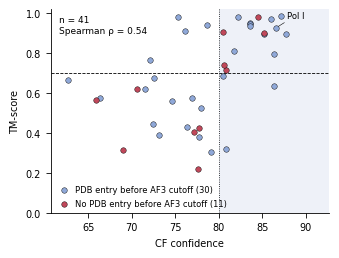

shape: (11, 4)
┌────────────┬────────┬───────────────┬──────────────────────┐
│ complex_ac ┆ pdb_id ┆ CF_confidence ┆ usalign_cpx_tm_score │
│ ---        ┆ ---    ┆ ---           ┆ ---                  │
│ str        ┆ str    ┆ f64           ┆ f64                  │
╞════════════╪════════╪═══════════════╪══════════════════════╡
│ CPX-1638   ┆ 7OCI   ┆ 85.2425       ┆ 0.89827              │
│ CPX-565    ┆ 9QDM   ┆ 84.533        ┆ 0.98048              │
│ CPX-545    ┆ 7TFK   ┆ 80.8477       ┆ 0.71387              │
│ CPX-1807   ┆ 7STE   ┆ 80.6246       ┆ 0.74011              │
│ CPX-1792   ┆ 7V2W   ┆ 80.5098       ┆ 0.90652              │
│ …          ┆ …      ┆ …             ┆ …                    │
│ CPX-1939   ┆ 7E8S   ┆ 77.6204       ┆ 0.21651              │
│ CPX-1706   ┆ 8QTN   ┆ 77.1824       ┆ 0.40656              │
│ CPX-2946   ┆ 8DAR   ┆ 70.5598       ┆ 0.6183               │
│ CPX-784    ┆ 8I6V   ┆ 69.0417       ┆ 0.31611              │
│ CPX-1810   ┆ 9VKW   ┆ 65.8376       ┆ 

In [4]:
# ---- panel C with leakage-free complexes highlighted, standalone

PARQUET = "/cluster/project/beltrao/kdammer/master_thesis/data/Pipeline/18_CP_model_based_on_pae/cf_pdb_structure_similarity/cf_pdb_eval_all_metrics.parquet"
EXPECTED_N_COMPLEXES = 41
TM_ACCEPTABLE_ACCURACY = 0.7
CF_CONFIDENCE_THRESHOLD = 80
POL1_AC = "CPX-1664"
OUT_PNG = Path("/cluster/project/beltrao/kdammer/master_thesis/notebooks/Figures/figure_defense") / "cf_confidence_vs_tm_leakage.png"
assert OUT_PNG.parent.is_dir(), f"{OUT_PNG.parent} does not exist"

# complexes without any identity-matching PDB entry released before the AF3 cutoff (30 Sep 2021)
LEAKAGE_FREE_COMPLEXES = {
    "CPX-1186", "CPX-1638", "CPX-1706", "CPX-1792", "CPX-1807", "CPX-1810",
    "CPX-1939", "CPX-2946", "CPX-545", "CPX-565", "CPX-784",
}
LEAKAGE_FREE_COLOUR = "#c0485a"
LEAKED_COLOUR = "#8fa8d8"

benchmark_all_outputs = pl.read_parquet(PARQUET)
assert "CF_confidence" not in benchmark_all_outputs.columns, "parquet already has CF_confidence, check which one to use"

confidence_by_output_path = {}
for combfold_output_dir in {Path(output_path).parent for output_path in benchmark_all_outputs["combfold_output_path"]}:
    confidence_file = combfold_output_dir / "confidence.txt"
    assert confidence_file.exists(), f"missing {confidence_file}"
    with open(confidence_file) as confidence_handle:
        confidence_by_output_path.update(dict(line.split() for line in confidence_handle if line.strip()))
outputs_without_confidence = set(benchmark_all_outputs["combfold_output_path"]) - set(confidence_by_output_path)
assert not outputs_without_confidence, f"{len(outputs_without_confidence)} outputs without confidence"

best_assembly_per_complex = (
    benchmark_all_outputs
    .with_columns(CF_confidence=pl.col("combfold_output_path").replace_strict(confidence_by_output_path, return_dtype=pl.Float64))
    .filter(pl.col("n_proteins") > 2)
    .sort("CF_confidence", descending=True)
    .group_by("complex_ac", maintain_order=True)
    .head(1)
    .with_columns(is_leakage_free=pl.col("complex_ac").is_in(list(LEAKAGE_FREE_COMPLEXES)))
)
assert best_assembly_per_complex.height == EXPECTED_N_COMPLEXES
assert LEAKAGE_FREE_COMPLEXES <= set(best_assembly_per_complex["complex_ac"]), "leakage-free complex missing in benchmark"
assert best_assembly_per_complex["usalign_cpx_tm_score"].null_count() == 0

spearman_rho_all, _ = spearmanr(best_assembly_per_complex["CF_confidence"], best_assembly_per_complex["usalign_cpx_tm_score"])

leakage_figure, axis_leakage_scatter = plt.subplots(figsize=(3.4, 2.6))
axis_leakage_scatter.axvspan(CF_CONFIDENCE_THRESHOLD, 100, color="#eef1f8", zorder=0, lw=0)
axis_leakage_scatter.axhline(TM_ACCEPTABLE_ACCURACY, color="black", lw=0.6, ls="--", zorder=1)
axis_leakage_scatter.axvline(CF_CONFIDENCE_THRESHOLD, color="black", lw=0.6, ls=":", zorder=1)

for is_leakage_free, point_colour, group_label in [
    (False, LEAKED_COLOUR, "PDB entry before AF3 cutoff"),
    (True, LEAKAGE_FREE_COLOUR, "No PDB entry before AF3 cutoff"),
]:
    group = best_assembly_per_complex.filter(pl.col("is_leakage_free") == is_leakage_free)
    n_group_accurate = int((group["usalign_cpx_tm_score"] > TM_ACCEPTABLE_ACCURACY).sum())
    axis_leakage_scatter.scatter(group["CF_confidence"], group["usalign_cpx_tm_score"], c=point_colour,
                                 s=16, edgecolor="black", linewidth=0.3, zorder=2,
                                 label=f"{group_label} ({group.height})")
    group_rho, _ = spearmanr(group["CF_confidence"], group["usalign_cpx_tm_score"])
    print(f"{group_label}: n = {group.height}, TM > {TM_ACCEPTABLE_ACCURACY}: {n_group_accurate}, "
          f"confident: {int((group['CF_confidence'] >= CF_CONFIDENCE_THRESHOLD).sum())}, Spearman rho = {group_rho:.2f}")

pol1_point = best_assembly_per_complex.filter(pl.col("complex_ac") == POL1_AC).row(0, named=True)
axis_leakage_scatter.annotate("Pol I", (pol1_point["CF_confidence"], pol1_point["usalign_cpx_tm_score"]),
                              xytext=(8, 9), textcoords="offset points", fontsize=6, ha="left", va="center",
                              arrowprops=dict(arrowstyle="-", lw=0.4, color="black", shrinkA=0, shrinkB=2))
axis_leakage_scatter.set_xlim(best_assembly_per_complex["CF_confidence"].min() - 2,
                              best_assembly_per_complex["CF_confidence"].max() + 5)
axis_leakage_scatter.set_ylim(0, 1.02)
axis_leakage_scatter.set_xlabel("CF confidence")
axis_leakage_scatter.set_ylabel("TM-score")
axis_leakage_scatter.text(0.03, 0.97, f"n = {best_assembly_per_complex.height}\nSpearman ρ = {spearman_rho_all:.2f}",
                          transform=axis_leakage_scatter.transAxes, ha="left", va="top", fontsize=6.5)
axis_leakage_scatter.legend(loc="lower left", frameon=False, fontsize=6, handletextpad=0.3, borderaxespad=0.2)
leakage_figure.tight_layout()
leakage_figure.savefig(OUT_PNG, dpi=300, bbox_inches="tight")
leakage_figure.savefig(OUT_PNG.with_suffix(".pdf"), bbox_inches="tight")
plt.show()

print(best_assembly_per_complex.filter("is_leakage_free")
      .select("complex_ac", "pdb_id", "CF_confidence", "usalign_cpx_tm_score").sort("CF_confidence", descending=True))

all: n = 41, Spearman rho = 0.54 (p = 2.6e-04), Pearson r = 0.51 (p = 7.5e-04)
PDB entry before AF3 cutoff: n = 30, TM > 0.7: 15, confident: 14 (of which TM > 0.7: 11), Spearman rho = 0.48 (p = 7.4e-03), Pearson r = 0.46 (p = 1.0e-02)
No PDB entry before AF3 cutoff: n = 11, TM > 0.7: 5, confident: 5 (of which TM > 0.7: 5), Spearman rho = 0.71 (p = 1.5e-02), Pearson r = 0.59 (p = 5.8e-02)


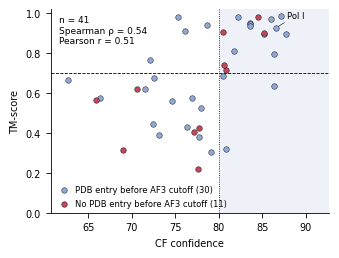

shape: (11, 4)
┌────────────┬────────┬───────────────┬──────────────────────┐
│ complex_ac ┆ pdb_id ┆ CF_confidence ┆ usalign_cpx_tm_score │
│ ---        ┆ ---    ┆ ---           ┆ ---                  │
│ str        ┆ str    ┆ f64           ┆ f64                  │
╞════════════╪════════╪═══════════════╪══════════════════════╡
│ CPX-1638   ┆ 7OCI   ┆ 85.2425       ┆ 0.89827              │
│ CPX-565    ┆ 9QDM   ┆ 84.533        ┆ 0.98048              │
│ CPX-545    ┆ 7TFK   ┆ 80.8477       ┆ 0.71387              │
│ CPX-1807   ┆ 7STE   ┆ 80.6246       ┆ 0.74011              │
│ CPX-1792   ┆ 7V2W   ┆ 80.5098       ┆ 0.90652              │
│ …          ┆ …      ┆ …             ┆ …                    │
│ CPX-1939   ┆ 7E8S   ┆ 77.6204       ┆ 0.21651              │
│ CPX-1706   ┆ 8QTN   ┆ 77.1824       ┆ 0.40656              │
│ CPX-2946   ┆ 8DAR   ┆ 70.5598       ┆ 0.6183               │
│ CPX-784    ┆ 8I6V   ┆ 69.0417       ┆ 0.31611              │
│ CPX-1810   ┆ 9VKW   ┆ 65.8376       ┆ 

In [3]:
# ---- panel C with leakage-free complexes highlighted (standalone, run after the imports)
from scipy.stats import pearsonr

PARQUET = "/cluster/project/beltrao/kdammer/master_thesis/data/Pipeline/18_CP_model_based_on_pae/cf_pdb_structure_similarity/cf_pdb_eval_all_metrics.parquet"
EXPECTED_N_COMPLEXES = 41
TM_ACCEPTABLE_ACCURACY = 0.7
CF_CONFIDENCE_THRESHOLD = 80
POL1_AC = "CPX-1664"


# complexes without any identity-matching PDB entry released before the AF3 cutoff (30 Sep 2021)
LEAKAGE_FREE_COMPLEXES = {
    "CPX-1186", "CPX-1638", "CPX-1706", "CPX-1792", "CPX-1807", "CPX-1810",
    "CPX-1939", "CPX-2946", "CPX-545", "CPX-565", "CPX-784",
}
assert len(LEAKAGE_FREE_COMPLEXES) == 11
LEAKAGE_FREE_COLOUR = "#c0485a"
LEAKED_COLOUR = "#8fa8d8"

benchmark_all_outputs = pl.read_parquet(PARQUET)
assert "CF_confidence" not in benchmark_all_outputs.columns, "parquet already has CF_confidence, check which one to use"

confidence_by_output_path = {}
for combfold_output_dir in {Path(output_path).parent for output_path in benchmark_all_outputs["combfold_output_path"]}:
    confidence_file = combfold_output_dir / "confidence.txt"
    assert confidence_file.exists(), f"missing {confidence_file}"
    with open(confidence_file) as confidence_handle:
        confidence_by_output_path.update(dict(line.split() for line in confidence_handle if line.strip()))
outputs_without_confidence = set(benchmark_all_outputs["combfold_output_path"]) - set(confidence_by_output_path)
assert not outputs_without_confidence, f"{len(outputs_without_confidence)} outputs without confidence"

best_assembly_per_complex = (
    benchmark_all_outputs
    .with_columns(CF_confidence=pl.col("combfold_output_path").replace_strict(confidence_by_output_path, return_dtype=pl.Float64))
    .filter(pl.col("n_proteins") > 2)
    .sort("CF_confidence", descending=True)
    .group_by("complex_ac", maintain_order=True)
    .head(1)
    .with_columns(is_leakage_free=pl.col("complex_ac").is_in(list(LEAKAGE_FREE_COMPLEXES)))
)
assert best_assembly_per_complex.height == EXPECTED_N_COMPLEXES
assert LEAKAGE_FREE_COMPLEXES <= set(best_assembly_per_complex["complex_ac"]), "leakage-free complex missing in benchmark"
assert best_assembly_per_complex["usalign_cpx_tm_score"].null_count() == 0

# correlations over all complexes
spearman_rho_all, spearman_p_all = spearmanr(best_assembly_per_complex["CF_confidence"], best_assembly_per_complex["usalign_cpx_tm_score"])
pearson_r_all, pearson_p_all = pearsonr(best_assembly_per_complex["CF_confidence"], best_assembly_per_complex["usalign_cpx_tm_score"])
print(f"all: n = {best_assembly_per_complex.height}, "
      f"Spearman rho = {spearman_rho_all:.2f} (p = {spearman_p_all:.1e}), Pearson r = {pearson_r_all:.2f} (p = {pearson_p_all:.1e})")

leakage_figure, axis_leakage_scatter = plt.subplots(figsize=(3.4, 2.6))
axis_leakage_scatter.axvspan(CF_CONFIDENCE_THRESHOLD, 100, color="#eef1f8", zorder=0, lw=0)
axis_leakage_scatter.axhline(TM_ACCEPTABLE_ACCURACY, color="black", lw=0.6, ls="--", zorder=1)
axis_leakage_scatter.axvline(CF_CONFIDENCE_THRESHOLD, color="black", lw=0.6, ls=":", zorder=1)

for is_leakage_free, point_colour, group_label in [
    (False, LEAKED_COLOUR, "PDB entry before AF3 cutoff"),
    (True, LEAKAGE_FREE_COLOUR, "No PDB entry before AF3 cutoff"),
]:
    group = best_assembly_per_complex.filter(pl.col("is_leakage_free") == is_leakage_free)
    n_group_accurate = int((group["usalign_cpx_tm_score"] > TM_ACCEPTABLE_ACCURACY).sum())
    n_group_confident = int((group["CF_confidence"] >= CF_CONFIDENCE_THRESHOLD).sum())
    n_group_confident_accurate = int(((group["CF_confidence"] >= CF_CONFIDENCE_THRESHOLD)
                                      & (group["usalign_cpx_tm_score"] > TM_ACCEPTABLE_ACCURACY)).sum())
    axis_leakage_scatter.scatter(group["CF_confidence"], group["usalign_cpx_tm_score"], c=point_colour,
                                 s=16, edgecolor="black", linewidth=0.3, zorder=2,
                                 label=f"{group_label} ({group.height})")
    group_rho, group_spearman_p = spearmanr(group["CF_confidence"], group["usalign_cpx_tm_score"])
    group_r, group_pearson_p = pearsonr(group["CF_confidence"], group["usalign_cpx_tm_score"])
    print(f"{group_label}: n = {group.height}, TM > {TM_ACCEPTABLE_ACCURACY}: {n_group_accurate}, "
          f"confident: {n_group_confident} (of which TM > {TM_ACCEPTABLE_ACCURACY}: {n_group_confident_accurate}), "
          f"Spearman rho = {group_rho:.2f} (p = {group_spearman_p:.1e}), Pearson r = {group_r:.2f} (p = {group_pearson_p:.1e})")

pol1_point = best_assembly_per_complex.filter(pl.col("complex_ac") == POL1_AC).row(0, named=True)
axis_leakage_scatter.annotate("Pol I", (pol1_point["CF_confidence"], pol1_point["usalign_cpx_tm_score"]),
                              xytext=(8, 9), textcoords="offset points", fontsize=6, ha="left", va="center",
                              arrowprops=dict(arrowstyle="-", lw=0.4, color="black", shrinkA=0, shrinkB=2))
axis_leakage_scatter.set_xlim(best_assembly_per_complex["CF_confidence"].min() - 2,
                              best_assembly_per_complex["CF_confidence"].max() + 5)
axis_leakage_scatter.set_ylim(0, 1.02)
axis_leakage_scatter.set_xlabel("CF confidence")
axis_leakage_scatter.set_ylabel("TM-score")
axis_leakage_scatter.text(0.03, 0.97,
                          f"n = {best_assembly_per_complex.height}\nSpearman ρ = {spearman_rho_all:.2f}\nPearson r = {pearson_r_all:.2f}",
                          transform=axis_leakage_scatter.transAxes, ha="left", va="top", fontsize=6.5)
axis_leakage_scatter.legend(loc="lower left", frameon=False, fontsize=6, handletextpad=0.3, borderaxespad=0.2)
leakage_figure.tight_layout()
leakage_figure.savefig(OUT_PNG, dpi=300, bbox_inches="tight")
plt.show()


print(best_assembly_per_complex.filter("is_leakage_free")
      .select("complex_ac", "pdb_id", "CF_confidence", "usalign_cpx_tm_score").sort("CF_confidence", descending=True))